# Spatial ATAC-seq and spatial ATAC-RNA-seq

DBiT-seq based assays put barcodes on a grid of microfluidic channels and so
give every 10-50 um pixel of a tissue section its own chromatin accessibility
profile: spatial-ATAC-seq (Deng et al., *Nature* 2022), and spatial
ATAC-RNA-seq and CUT&Tag-RNA-seq, which add the transcriptome of the same
pixel (Zhang et al., *Nature* 2023). Each pixel ("spot") is a mini-bulk of a
few cells. This tutorial goes from fragments to spatial domains:

| Step | Epione function |
|---|---|
| fragments + barcode -> (x, y) table + tissue image -> AnnData / MuData | `epi.io.read_spatial_atac`, `epi.io.read_spatial_atac_rna`, `epi.io.add_spatial` |
| per-spot QC on the tissue | `epi.pp.tsse`, `epi.pl.spatial_qc` |
| spot maps of any value | `epi.pl.spatial` |
| spot graph, neighbourhood smoothing, Moran's I | `epi.tl.spatial_neighbors`, `epi.tl.spatial_smooth`, `epi.tl.spatial_moran` |
| spatial domains | `epi.tl.spatial_domains` |
| ATAC + RNA integration | `epi.tl.spatialglue` (port of SpatialGlue, Long et al., *Nature Methods* 2024) |

The AnnData follow the scanpy / squidpy layout (`obsm["spatial"]`,
`uns["spatial"][library_id]`), so `sc.pl.spatial` and `squidpy.gr.*` work on
them too.

**Data.** A human hippocampus section profiled by spatial ATAC-RNA-seq at
50 um (Zhang et al. 2023, GEO GSE205055: 2,500 spots, 45 M fragments), read
from the raw GEO files. In the last part we rerun SpatialGlue on the mouse
brain spatial ATAC-RNA-seq data released with the SpatialGlue paper.

## Setup

In [1]:
import os
import pathlib
import warnings

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi

warnings.filterwarnings("ignore")
epi.pl.plot_set()
DATA = pathlib.Path(os.environ.get("EPIONE_SPATIAL_DIR", "data_spatial"))
genome = epi.utils.genome.hg38

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Read fragments, RNA and spot positions

`zhang2023_hippocampus_atac_rna` downloads the three GEO files (fragments,
RNA counts, and the Space Ranger style `spatial/` folder with
`tissue_positions_list.csv`, `scalefactors_json.json` and the tissue image).
`read_spatial_atac_rna` scans the fragments of the on-tissue spots only (the
tissue mask in `in_tissue`), reads the RNA table, aligns the two modalities on
the spot barcode (the fragments carry a `-1` suffix, the RNA table does not)
and attaches the coordinates and the image. A bare DBiT whitelist with
columns `barcode, x, y` works as `positions` too.

In [2]:
paths = epi.datasets.zhang2023_hippocampus_atac_rna(data_dir=DATA / "zhang2023_hippocampus")
mdata = epi.io.read_spatial_atac_rna(
    paths["fragments"], paths["rna"], paths["positions"], genome,
    spatial_dir=paths["spatial_dir"], library_id="hippocampus",
)
atac, rna = mdata["atac"], mdata["rna"]
mdata

└─ scanning data_spatial/zhang2023_hippocampus/GSM6206884_HumanBrain_50um_fragments.tsv.gz


  └─ imported 2,500 cells  (44,920,825 unique fragments)


MuData object with n_obs × n_vars = 2500 × 29293
  uns:	'spatial'
  obsm:	'spatial'
  2 modalities
    rna:	2500 × 29293
      obs:	'in_tissue', 'array_row', 'array_col', 'library_id'
      uns:	'spatial'
      obsm:	'spatial'
    atac:	2500 × 0
      obs:	'n_fragment', 'frac_dup', 'frac_mito', 'in_tissue', 'array_row', 'array_col', 'library_id'
      uns:	'files', 'reference_sequences', 'spatial'
      obsm:	'spatial'

## Spot QC on the tissue

TSS enrichment and unique fragments per spot, drawn as 50 um squares on the
section. The straight lines in the fragment map follow the microfluidic
channels: in DBiT data one row or column of the barcode grid can be deeper
than its neighbours. This is a technical effect that downstream steps
should not mistake for biology.

In [3]:
genes = epi.utils.get_gene_annotation(genome)
epi.pp.tsse(atac, genes)
atac.obs[["n_fragment", "tsse", "frac_dup"]].describe().round(2)

└─ Computing TSS enrichment score for adata...
└─ Computing TSS enrichment score for adata...


Fetching Regions...:   0%|          | 0/19978 [00:00<?, ?it/s]

Fetching Regions...:   0%|          | 77/19978 [00:00<00:25, 767.20it/s]

Fetching Regions...:   1%|          | 161/19978 [00:00<00:24, 809.13it/s]

Fetching Regions...:   1%|▏         | 280/19978 [00:00<00:20, 980.42it/s]

...

Fetching Regions...:  99%|█████████▉| 19746/19978 [00:20<00:00, 1591.85it/s]

Fetching Regions...: 100%|█████████▉| 19946/19978 [00:20<00:00, 1711.20it/s]

Fetching Regions...: 100%|██████████| 19978/19978 [00:20<00:00, 984.39it/s] 

  └─ Added TSS enrichment score to adata.obs['tss_score']
└─ Created TSS enrichment score
  └─ Added TSS enrichment score to tss_pileup.obs['tss_score']
  └─ Returned TSS enrichment score
  └─ Added TSS enrichment score to adata.obs['tsse']


,n_fragment,tsse,frac_dup
count,2500.00,2500.00,2500.00
mean,17968.33,8.06,0.35
std,23839.79,3.63,0.02
min,307.00,0.21,0.22
25%,4708.50,5.72,0.35
50%,9898.00,7.39,0.36
75%,19972.50,9.61,0.36
max,188505.00,55.45,0.38


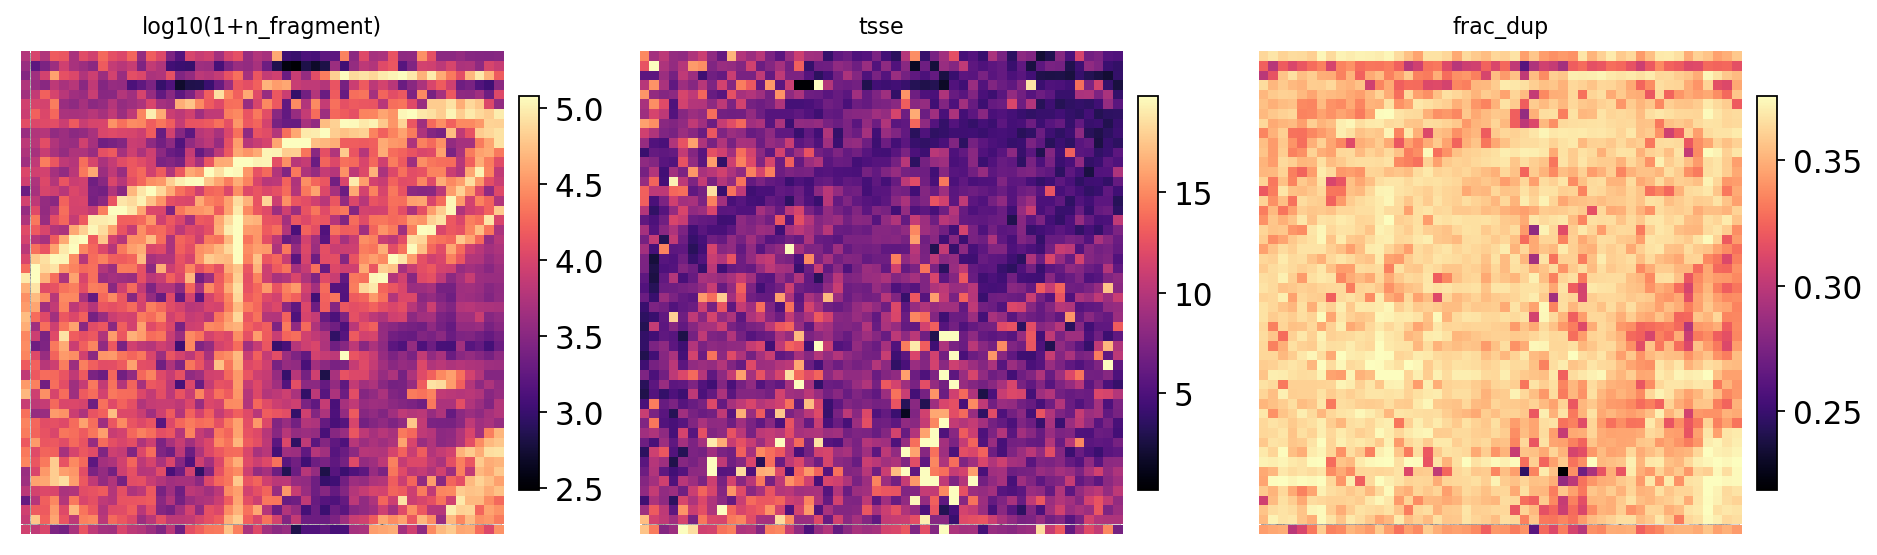

In [4]:
epi.pl.spatial_qc(atac, keys=("n_fragment", "tsse", "frac_dup"), show=False)
plt.show()

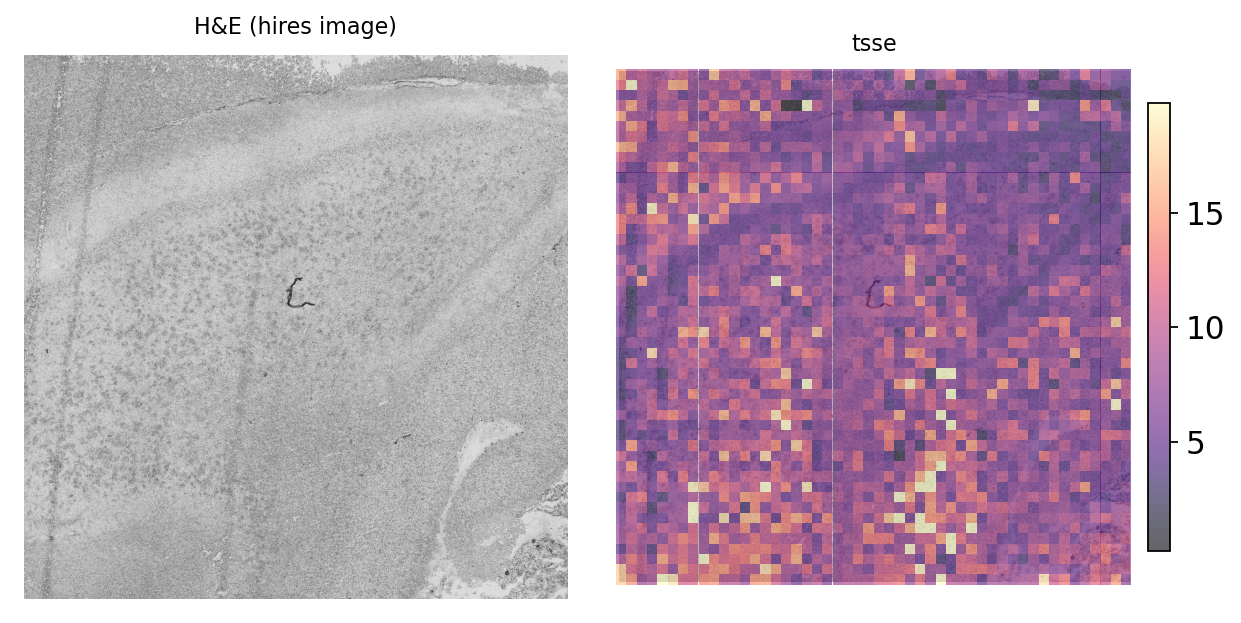

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
epi.pl.spatial(atac, None, alpha=0.0, ax=axs[0], title="H&E (hires image)", show=False)
epi.pl.spatial(atac, "tsse", alpha=0.6, ax=axs[1], show=False)
plt.tight_layout(); plt.show()

## Tile matrix, LSI and the spot graph

The usual scATAC steps apply unchanged to spots: a 500 bp tile matrix, the
50,000 most accessible tiles, and ArchR's iterative LSI. The spot graph is the
4-connected DBiT grid (`coord_type="grid"`); `coord_type="generic"` builds a
k-nearest-neighbour graph on the coordinates instead, for Visium or
irregular layouts.

In [6]:
epi.pp.add_tile_matrix(atac, bin_size=500)
epi.pp.select_features(atac, n_features=50000)
tiles = atac[:, atac.var["selected"].to_numpy(bool)].copy()
epi.tl.iterative_lsi(tiles, n_components=30, iterations=2, var_features=25000,
                     resolution=0.5, n_neighbors=20, depth_col="n_fragment", seed=1)
epi.tl.spatial_neighbors(tiles, coord_type="grid", n_neighs=4)
tiles

└─ building tile matrix: 2,500 cells × 6,176,584 tiles (500 bp bins, strategy=paired-insertion)


  └─ tile matrix nnz=64,090,905


└─ Selected 50,000 features.


  └─ [iterative_lsi] Initial feature set: 49,769 / 50,000
  └─ [iterative_lsi] Iter 1/2 | fit on 2,500 cells x 49,769 features


computing neighbors


...

running Leiden clustering


    finished: found 3 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


  └─ [iterative_lsi]   -> 3 clusters; selected 25,000 variable features for next round
  └─ [iterative_lsi] Iter 2/2 | fit on 2,500 cells x 25,000 features


  └─ [iterative_lsi] Done. Stored embedding (2,500 x 29) in adata.obsm['X_iterative_lsi']


AnnData object with n_obs × n_vars = 2500 × 50000
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'in_tissue', 'array_row', 'array_col', 'library_id', 'tss_score', 'tsse'
    var: 'count', 'selected'
    uns: 'files', 'reference_sequences', 'spatial', 'library_tsse', 'X_iterative_lsi', 'spatial_neighbors'
    obsm: 'spatial', 'X_iterative_lsi'
    varm: 'X_iterative_lsi_loadings'
    obsp: 'spatial_connectivities', 'spatial_distances'

## Neighbourhood smoothing and spatial domains

A 50 um spot of a 45 M-fragment section holds about 10,000 fragments, so
spot-level embeddings are noisy. `spatial_smooth` replaces every spot by
`(1 - lam) * itself + lam * mean of its grid neighbours`. It is a plain
smoother, not a published method. `spatial_domains` clusters an embedding into a fixed number of
domains: PCA, then a Gaussian mixture (mclust, `EEE` covariance, the routine
SpatialGlue uses, via the pure-Python pymclustR port), a Leiden resolution
search, or k-means. Moran's I of the one-hot domain labels measures how
spatially coherent the domains are (smoothing makes domains more coherent
partly by construction, so this is a description, not a score of
correctness). On this section ATAC alone separates few domains: one mixture
component takes most spots, with or without smoothing. The joint RNA + ATAC
model further down resolves the hippocampal layers.

In [7]:
epi.tl.spatial_smooth(tiles, use_rep="X_iterative_lsi", lam=0.5)
for rep, key in [("X_iterative_lsi", "domain_lsi"), ("X_iterative_lsi_smooth", "domain_lsi_smooth")]:
    epi.tl.spatial_domains(tiles, 8, use_rep=rep, method="mclust", key_added=key)

def domain_moran(a, key):
    lab = a.obs[key].astype(str)
    a.obsm["_onehot"] = pd.get_dummies(lab).to_numpy(float)
    return float(epi.tl.spatial_moran(a, use_rep="_onehot").mean())

pd.Series({k: domain_moran(tiles, k) for k in ["domain_lsi", "domain_lsi_smooth"]},
          name="mean Moran's I of domains").round(3)

domain_lsi           0.188
domain_lsi_smooth    0.475
Name: mean Moran's I of domains, dtype: float64

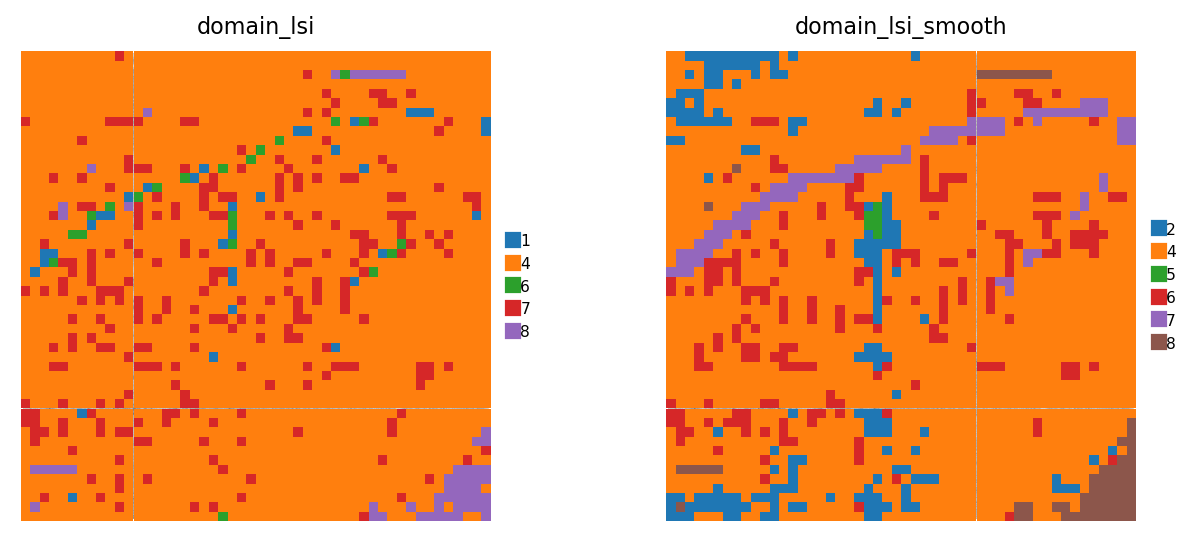

In [8]:
epi.pl.spatial(tiles, ["domain_lsi", "domain_lsi_smooth"], show=False)
plt.show()

## Gene scores next to expression

ArchR gene scores summarise accessibility around each gene. Spatial
ATAC-RNA-seq measures expression in the same spot, so the two can be put side
by side: SNAP25 (neurons), PROX1 (dentate gyrus granule cells), MBP
(oligodendrocytes, white matter). With about 10,000 fragments per spot a
single gene's score is sparse, so we also show it after one round of grid
smoothing (`spatial_smooth` works on matrices as well as embeddings). The
spot-level agreement with RNA is weak for these genes (table below), which
is typical for gene scores at this depth; domains and joint embeddings,
which pool many regions, are more robust than single genes.

  └─ [gene_score] genes: 19,923 on 23 chroms (after excluding ['chrY', 'chrM'])


  └─ [gene_score] chrom-by-chrom ArchR path (fragments → uniq_tiles → W @ matGS)


  └─ [gene_score] chr=chr1  genes=2,061


  └─ [gene_score] chr=chr10  genes=730


  └─ [gene_score] chr=chr11  genes=1,318


...

  └─ [gene_score] chr=chr9  genes=774


  └─ [gene_score] chr=chrX  genes=845


  └─ [gene_score] done. obsm['gene_score'] = (2500, 19923) float32 (uns[gene_score_gene_names]: 19,923 genes)


normalizing counts per cell


    finished (0:00:00)


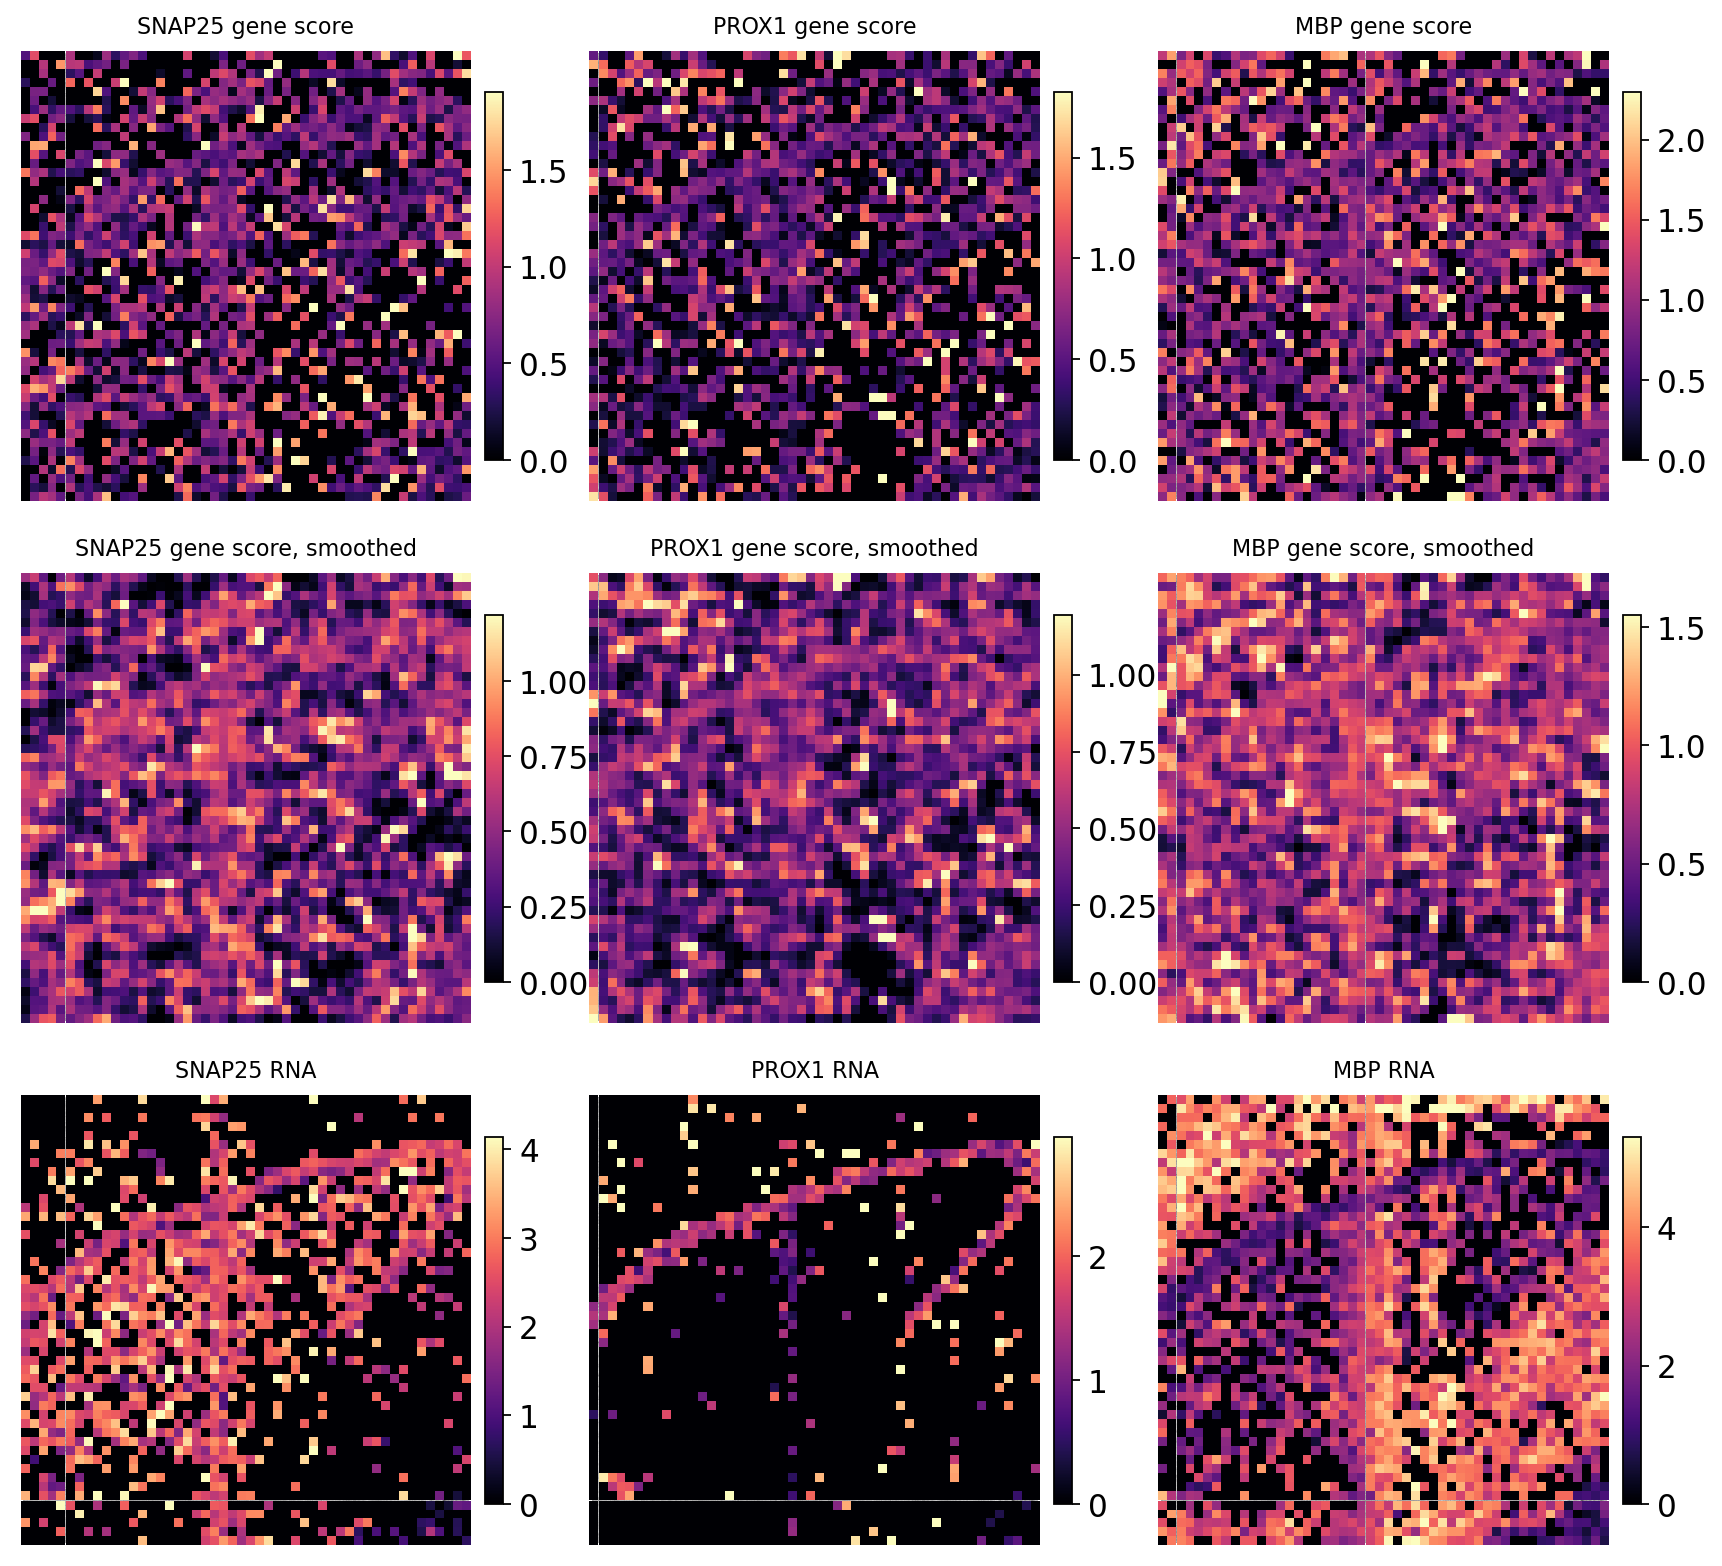

In [9]:
epi.tl.add_gene_score_matrix(atac, genes)
gs = ad.AnnData(np.log1p(atac.obsm["gene_score"]), obs=atac.obs[["array_row", "array_col"]].copy(),
                var=pd.DataFrame(index=pd.Index(atac.uns["gene_score_gene_names"]).astype(str)))
gs.var_names_make_unique()
gs.obsm["spatial"], gs.uns["spatial"] = atac.obsm["spatial"], atac.uns["spatial"]
gs.obsp["spatial_connectivities"] = tiles.obsp["spatial_connectivities"]
markers = ["SNAP25", "PROX1", "MBP"]
gs = gs[:, markers].copy()
epi.tl.spatial_smooth(gs, use_rep=None, lam=0.5)          # -> gs.layers["smoothed"]

rna_n = rna.copy()
sc.pp.normalize_total(rna_n, target_sum=1e4); sc.pp.log1p(rna_n)
fig, axs = plt.subplots(3, 3, figsize=(11, 10))
for j, g in enumerate(markers):
    epi.pl.spatial(gs, g, ax=axs[0, j], title=f"{g} gene score", show=False)
    epi.pl.spatial(gs, g, layer="smoothed", ax=axs[1, j], title=f"{g} gene score, smoothed", show=False)
    epi.pl.spatial(rna_n, g, ax=axs[2, j], title=f"{g} RNA", show=False)
plt.tight_layout(); plt.show()

In [10]:
from scipy.stats import spearmanr
rows = []
for g in markers:
    y = rna_n[:, g].X.toarray().ravel()
    rows.append((g, spearmanr(gs[:, g].X.ravel(), y).statistic,
                 spearmanr(gs[:, g].layers["smoothed"].ravel(), y).statistic))
pd.DataFrame(rows, columns=["gene", "Spearman vs RNA (raw score)", "Spearman vs RNA (smoothed score)"]).round(3)

,gene,Spearman vs RNA (raw score),Spearman vs RNA (smoothed score)
0,SNAP25,0.123,0.151
1,PROX1,0.108,0.109
2,MBP,-0.029,-0.025


## Motif deviations on the section

chromVAR deviations of JASPAR motifs over the 50,000 tiles (MOODS scan,
GC-matched background tiles from the genome), drawn on the tissue: SOX10 for
oligodendrocyte lineage, NEUROD2 for neurons, and CTCF as a ubiquitous
control. Per-spot deviations are noisy at this depth. Moran's I measures
spatial structure; note that smoothing raises it for every motif by
construction (the CTCF control included), so a smoothed motif map should be
compared with the control rather than with the raw value. Here the raw
values are all low: at 50 um and ~10,000 fragments per spot, single-motif
deviations carry little spatial signal on this section.

In [11]:
epi.tl.add_motif_matrix(tiles, genome_fasta=str(genome.fasta), verbose=False)
epi.tl.add_background_peaks(tiles, n_iterations=25, genome_fasta=str(genome.fasta), seed=1)
epi.tl.compute_deviations(tiles, verbose=False)
# spots x motifs deviation z-scores, as an AnnData that keeps the spot positions
dev = ad.AnnData(np.asarray(tiles.obsm["motif_deviations"], dtype=np.float32),
                 obs=tiles.obs[["array_row", "array_col"]].copy(),
                 var=pd.DataFrame(index=pd.Index(tiles.uns["motif_deviations_names"]).astype(str)))
dev.var_names_make_unique()
dev.obsm["spatial"], dev.uns["spatial"] = tiles.obsm["spatial"], tiles.uns["spatial"]
dev.obsp["spatial_connectivities"] = tiles.obsp["spatial_connectivities"]
epi.tl.spatial_smooth(dev, use_rep=None, lam=0.5)          # -> dev.layers["smoothed"]
dev

  0%|          | 0/50000 [00:00<?, ?it/s]

  4%|▎         | 1801/50000 [00:00<00:02, 18008.64it/s]

  8%|▊         | 4042/50000 [00:00<00:02, 20311.25it/s]

 12%|█▏        | 6071/50000 [00:00<00:02, 16560.85it/s]

 16%|█▌        | 8059/50000 [00:00<00:02, 17679.97it/s]

...

 34%|███▍      | 16882/50000 [00:00<00:00, 168811.71it/s]

 68%|██████▊   | 33795/50000 [00:00<00:00, 168991.45it/s]

100%|██████████| 50000/50000 [00:00<00:00, 169865.45it/s]

  └─ [bg_peaks] built 50,000 peaks × 25 bg peers


AnnData object with n_obs × n_vars = 2500 × 879
    obs: 'array_row', 'array_col'
    uns: 'spatial'
    obsm: 'spatial'
    layers: 'smoothed'
    obsp: 'spatial_connectivities'

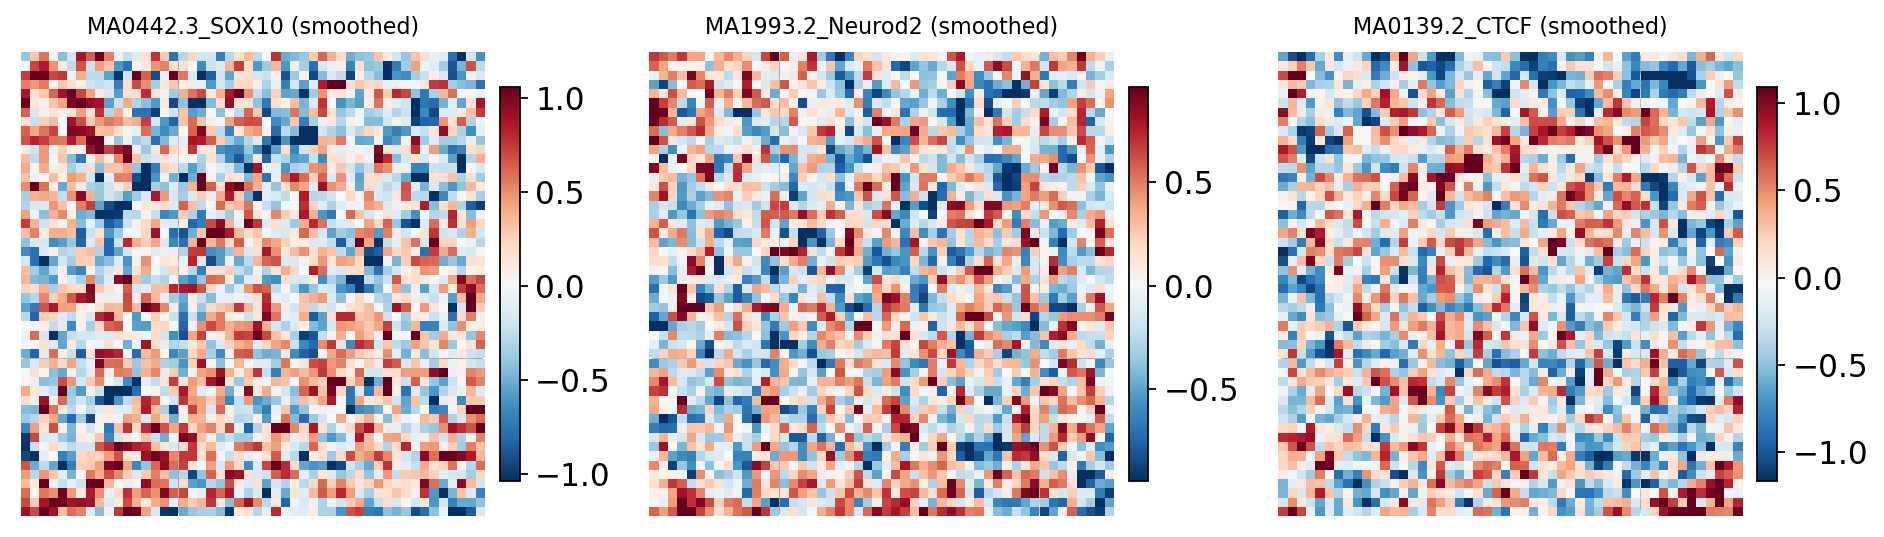

,"Moran's I, raw","Moran's I, smoothed"
MA0442.3_SOX10,0.050,0.457
MA1993.2_Neurod2,0.024,0.447
MA0139.2_CTCF,0.068,0.499


In [12]:
def find(tf):
    # motif names are "<JASPAR id>_<TF>"; take the first matrix of that TF
    return next(v for v in dev.var_names if v.split("_", 1)[-1].upper() == tf)
show = [find(t) for t in ["SOX10", "NEUROD2", "CTCF"]]
epi.pl.spatial(dev, show, layer="smoothed", cmap="RdBu_r", vmin="p2", vmax="p98", ncols=3,
               title=[f"{m} (smoothed)" for m in show], show=False)
plt.show()
pd.DataFrame({"Moran's I, raw": epi.tl.spatial_moran(dev, features=show),
              "Moran's I, smoothed": epi.tl.spatial_moran(dev, features=show, layer="smoothed")}).round(3)

## Joint ATAC + RNA domains with SpatialGlue

SpatialGlue encodes each modality with a graph convolution on a spatial graph
and on a feature graph, mixes the two with an attention layer, mixes the
modalities with a second attention layer, and trains by reconstructing both
inputs. `epi.tl.spatialglue_preprocess` runs the official tutorial's
preprocessing (RNA: 3,000 HVGs, scaled, PCA 50; ATAC: LSI). The modality
weights `alpha` tell, per spot, whether RNA or ATAC drives the joint
embedding.

In [13]:
rna_sg = rna.copy()
atac_sg = tiles.copy()
del atac_sg.obsm["X_iterative_lsi_smooth"]
rna_sg, atac_sg = epi.tl.spatialglue_preprocess(rna_sg, atac_sg)
import mudata as md
sg = md.MuData({"rna": rna_sg, "atac": atac_sg})
sg.obsm["spatial"] = rna_sg.obsm["spatial"]
sg.uns["spatial"] = rna_sg.uns["spatial"]
out = epi.tl.spatialglue(sg, modalities=("rna", "atac"), device="cpu", verbose=False)
epi.tl.spatial_domains(sg, 8, use_rep="SpatialGlue", method="mclust", key_added="domain_spatialglue")
sg.obs["alpha_rna"] = sg.obsm["SpatialGlue_alpha"][:, 0]
tiles_sub = tiles[sg.obs_names].copy()          # spots kept by the RNA filter
sg.obsp["spatial_connectivities"] = tiles_sub.obsp["spatial_connectivities"]
pd.Series({"ATAC smoothed LSI": domain_moran(tiles_sub, "domain_lsi_smooth"),
           "SpatialGlue (RNA+ATAC)": domain_moran(sg, "domain_spatialglue")},
          name="mean Moran's I of domains").round(3)

filtered out 10726 genes that are detected in less than 10 cells


filtered out 238 cells that have less than 200 genes expressed


extracting highly variable genes


--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)


normalizing counts per cell


    finished (0:00:00)


ATAC smoothed LSI         0.491
SpatialGlue (RNA+ATAC)    0.598
Name: mean Moran's I of domains, dtype: float64

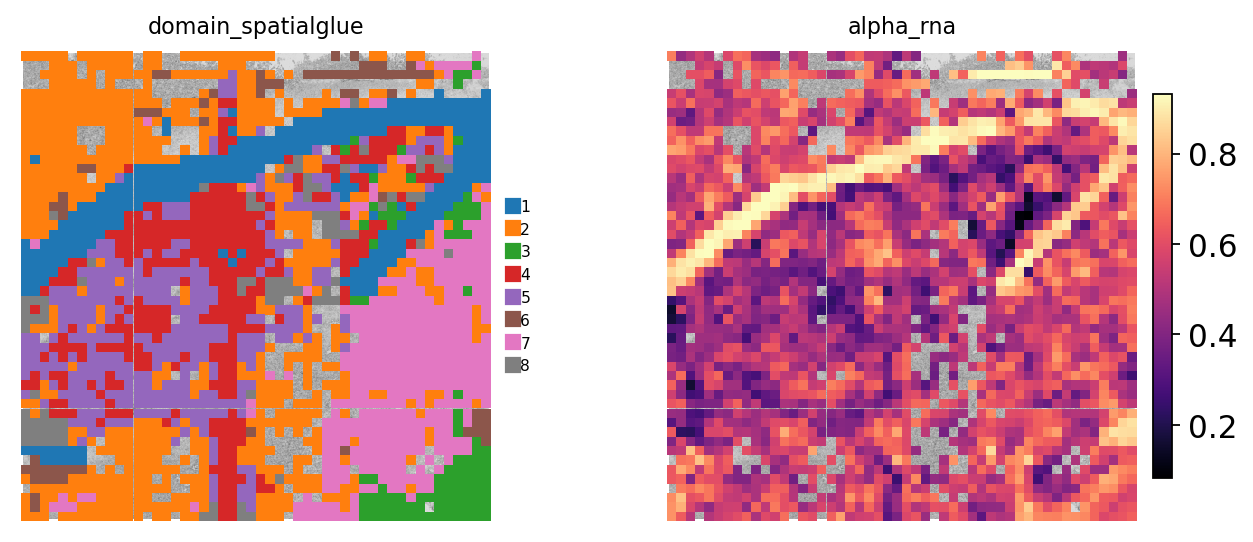

In [14]:
epi.pl.spatial(sg, ["domain_spatialglue", "alpha_rna"], show=False)
plt.show()

## SpatialGlue on its own published dataset

The mouse brain (P22) spatial ATAC-RNA-seq data of the SpatialGlue paper,
from Zenodo, run with the official tutorial settings (1,600 epochs, 18
domains). The Epione port reproduces the official implementation exactly:
with the same seed and inputs the joint embeddings are identical, and over
three seeds the agreement of the domains with the original authors' ATAC and
RNA clusters matches (gates and numbers in
`tests/parity/spatial_atac/MANIFEST.md`).

In [15]:
from sklearn.metrics import adjusted_rand_score
mrna, matac = epi.datasets.spatialglue_mouse_brain(data_dir=DATA / "spatialglue")
mrna, matac = epi.tl.spatialglue_preprocess(mrna, matac, random_seed=2022)
mb = md.MuData({"rna": mrna, "atac": matac})
mb.obsm["spatial"] = mrna.obsm["spatial"]
epi.tl.spatialglue(mb, modalities=("rna", "atac"), random_seed=2022, device="cpu", verbose=False)
epi.tl.spatial_domains(mb, 18, use_rep="SpatialGlue", method="mclust", key_added="SpatialGlue")
pd.Series({ref: adjusted_rand_score(mrna.obs[ref].astype(str), mb.obs["SpatialGlue"])
           for ref in ["ATAC_clusters", "RNA_clusters"]}, name="ARI").round(3)

filtered out 6610 genes that are detected in less than 10 cells


filtered out 19 cells that have less than 200 genes expressed


extracting highly variable genes


--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)


normalizing counts per cell


    finished (0:00:00)


ATAC_clusters    0.269
RNA_clusters     0.245
Name: ARI, dtype: float64

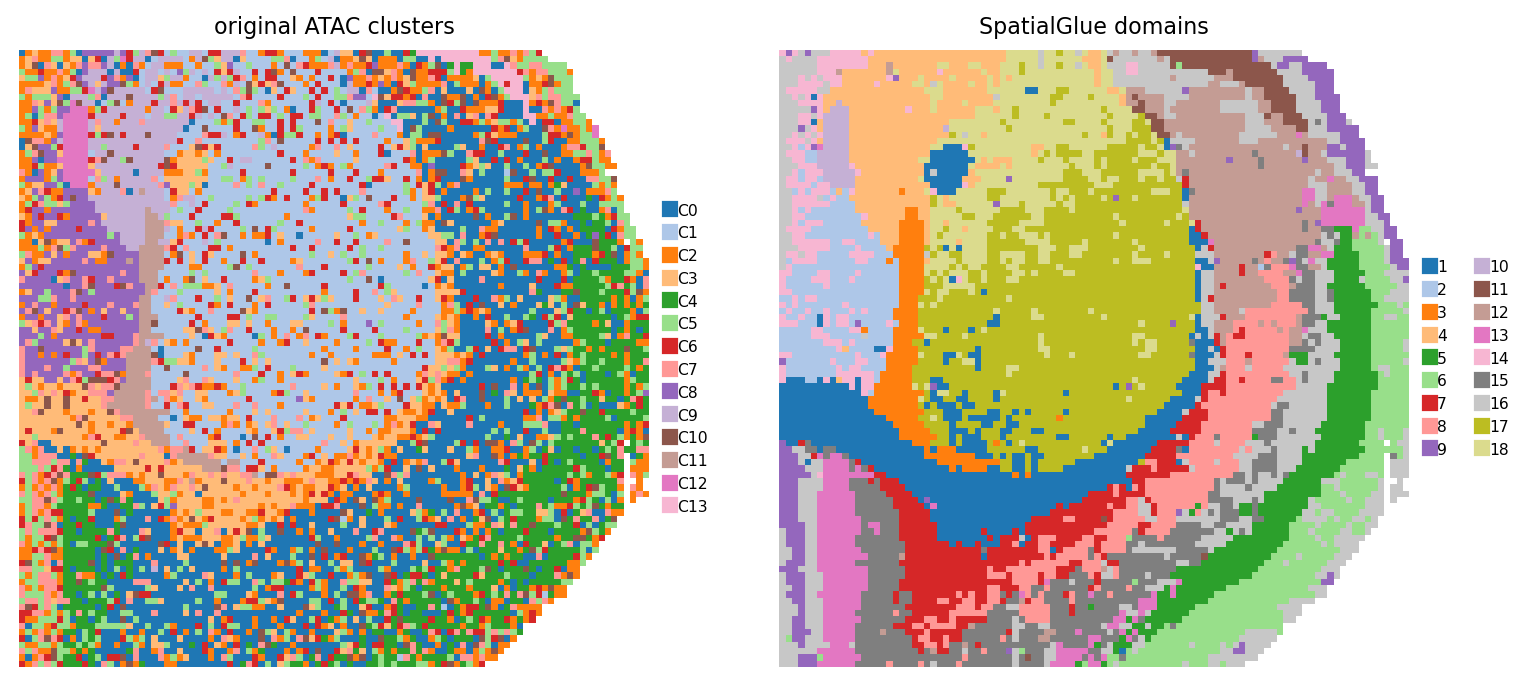

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
mrna.obs["SpatialGlue"] = pd.Categorical(mb.obs["SpatialGlue"].astype(int).to_numpy())
epi.pl.spatial(mrna, "ATAC_clusters", ax=axs[0], title="original ATAC clusters", show=False)
epi.pl.spatial(mrna, "SpatialGlue", ax=axs[1], title="SpatialGlue domains", show=False)
plt.tight_layout(); plt.show()

## Notes

* Visium-style releases (Space Ranger `spatial/` folder, e.g. AtlasXomics
  DBiT data on GEO) and bare DBiT barcode whitelists are both read by
  `epi.io.read_spatial_positions`. `epi.io.add_spatial` attaches positions to
  any AnnData built elsewhere, such as a peak matrix.
* `epi.tl.spatialglue` is a port of SpatialGlue v1.1.5 and keeps its
  AGPL-3.0 licence (the rest of Epione is GPL-3.0). R is not needed: mclust
  runs through pymclustR.
* A spot is a mixture of cells, so spot domains mix composition and cell state.
* Epione's RNA-to-ATAC translators (`epi.translate`) can predict chromatin
  accessibility for spatial transcriptomics panels that have no ATAC
  measurement. Sections profiled like this one give spot-matched RNA and ATAC
  to check such predictions against.